# AI-Powered Food Waste Prediction & Smart Inventory Optimization

## Exploratory Data Analysis (EDA)

### Objective
To understand the dataset, identify patterns, detect anomalies, and generate business insights before building machine learning models.

In [1]:
# Import required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import plotly.express as px

# Display all columns in the dataset
pd.set_option("display.max_columns", None)

In [2]:
# Load the processed dataset

df = pd.read_csv("../data/processed/food_waste_master_dataset.csv")

In [3]:
df.head()

,Store_ID,Product_ID,Inventory_Received,Inventory_Sold,Inventory_Remaining,Product_Name,Category,Brand,Shelf_Life_Days,Unit_Price,Unit,Storage_Type,Store_Name,City,State,Region,Store_Type,Store_Size,Opening_Year,Demand_Score,Demand_Level,Month,Promotion,Discount_Percentage,Date,Temperature,Humidity,Rainfall,Weather,Weekend,Holiday,Expiry_Days_Left,Waste_Quantity,Waste_Cost,Waste_Risk,Inventory_Recommendation
0,S001,P001,410,229,181,Milk 500ml,Dairy,Amul,5,32,500 ml,Refrigerated,FreshMart Hyderabad,Hyderabad,Telangana,South,Hypermarket,Large,2016,59,Low,1,Yes,15,2025-11-26,30,71,0,Cloudy,1,0,3,18.55,593.60,Low,Increase Order
1,S001,P002,148,142,6,Curd 400g,Dairy,Amul,10,45,400 g,Refrigerated,FreshMart Hyderabad,Hyderabad,Telangana,South,Hypermarket,Large,2016,62,Medium,1,No,0,2025-12-10,16,88,14,Rainy,0,0,6,0.57,25.65,Low,Increase Order
2,S001,P003,143,74,69,Butter 200g,Dairy,Amul,90,65,200 g,Refrigerated,FreshMart Hyderabad,Hyderabad,Telangana,South,Hypermarket,Large,2016,55,Low,1,No,0,2025-07-08,31,68,0,Cloudy,0,0,54,7.76,504.40,Low,Increase Order
3,S001,P004,288,266,22,Paneer 200g,Dairy,Amul,7,90,200 g,Refrigerated,FreshMart Hyderabad,Hyderabad,Telangana,South,Hypermarket,Large,2016,63,Medium,1,Yes,15,2025-06-01,29,52,26,Rainy,0,0,4,2.04,183.60,Low,Increase Order
4,S001,P005,361,353,8,Cheese Slices,Dairy,Amul,120,140,200 g,Refrigerated,FreshMart Hyderabad,Hyderabad,Telangana,South,Hypermarket,Large,2016,73,Medium,1,No,0,2025-11-30,26,42,19,Rainy,1,0,72,0.54,75.60,Low,Increase Order


In [4]:
df.shape

(3000, 36)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 36 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Store_ID                  3000 non-null   object 
 1   Product_ID                3000 non-null   object 
 2   Inventory_Received        3000 non-null   int64  
 3   Inventory_Sold            3000 non-null   int64  
 4   Inventory_Remaining       3000 non-null   int64  
 5   Product_Name              3000 non-null   object 
 6   Category                  3000 non-null   object 
 7   Brand                     3000 non-null   object 
 8   Shelf_Life_Days           3000 non-null   int64  
 9   Unit_Price                3000 non-null   int64  
 10  Unit                      3000 non-null   object 
 11  Storage_Type              3000 non-null   object 
 12  Store_Name                3000 non-null   object 
 13  City                      3000 non-null   object 
 14  State   

In [6]:
df["Date"] = pd.to_datetime(df["Date"])

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 36 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   Store_ID                  3000 non-null   object        
 1   Product_ID                3000 non-null   object        
 2   Inventory_Received        3000 non-null   int64         
 3   Inventory_Sold            3000 non-null   int64         
 4   Inventory_Remaining       3000 non-null   int64         
 5   Product_Name              3000 non-null   object        
 6   Category                  3000 non-null   object        
 7   Brand                     3000 non-null   object        
 8   Shelf_Life_Days           3000 non-null   int64         
 9   Unit_Price                3000 non-null   int64         
 10  Unit                      3000 non-null   object        
 11  Storage_Type              3000 non-null   object        
 12  Store_Name          

In [8]:
df.describe()

,Inventory_Received,Inventory_Sold,Inventory_Remaining,Shelf_Life_Days,Unit_Price,Opening_Year,Demand_Score,Month,Discount_Percentage,Date,Temperature,Humidity,Rainfall,Weekend,Holiday,Expiry_Days_Left,Waste_Quantity,Waste_Cost
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.00000,3000.000000,3000.000000,3000.0,3000.0000,3000,3000.000000,3000.000000,3000.000000,3000.000000,3000.00000,3000.000000,3000.000000,3000.000000
mean,300.246333,175.243667,125.002667,119.840000,140.87000,2017.900000,64.742667,1.0,9.6000,2025-07-04 00:10:33.600000256,28.881333,67.427333,15.000667,0.305000,0.01100,71.860000,10.988947,1558.255687
min,100.000000,50.000000,0.000000,2.000000,23.00000,2015.000000,30.000000,1.0,0.0000,2025-01-01 00:00:00,15.000000,40.000000,0.000000,0.000000,0.00000,1.000000,0.000000,0.000000
25%,198.000000,97.000000,44.000000,11.500000,62.25000,2016.000000,47.000000,1.0,0.0000,2025-04-05 00:00:00,25.000000,54.000000,0.000000,0.000000,0.00000,6.750000,2.320000,213.600000
50%,298.000000,151.000000,102.000000,180.000000,120.00000,2018.000000,65.000000,1.0,5.0000,2025-07-05 00:00:00,29.000000,67.000000,0.000000,0.000000,0.00000,108.000000,6.830000,704.160000
75%,402.000000,235.000000,187.000000,180.000000,190.50000,2020.000000,82.000000,1.0,16.2500,2025-10-02 00:00:00,33.000000,81.000000,27.000000,1.000000,0.00000,108.000000,15.825000,1961.535000
max,500.000000,493.000000,442.000000,730.000000,347.00000,2021.000000,100.000000,1.0,30.0000,2025-12-31 00:00:00,42.000000,95.000000,80.000000,1.000000,1.00000,438.000000,70.880000,22231.890000
std,117.227629,97.541115,97.990343,110.362831,94.10837,1.972637,20.589474,0.0,10.7879,NaN,6.261122,15.792209,24.166865,0.460484,0.10432,66.263444,11.780831,2219.489963


In [9]:
df["Date"].dtype

dtype('<M8[ns]')

In [10]:
df["Month"] = df["Date"].dt.month

In [11]:
df["Month"].head()

0    11
1    12
2     7
3     6
4    11
Name: Month, dtype: int32

In [12]:
df["Month"].value_counts().sort_index()

Month
1     235
2     225
3     250
4     257
5     250
6     251
7     244
8     275
9     257
10    234
11    282
12    240
Name: count, dtype: int64

## Observation

- The `Month` column has been successfully extracted from the `Date` column.
- The dataset contains records for all 12 months.
- The monthly distribution is reasonably balanced, making it suitable for seasonal and trend analysis.

In [13]:
df.isnull().sum()

Store_ID                    0
Product_ID                  0
Inventory_Received          0
Inventory_Sold              0
Inventory_Remaining         0
Product_Name                0
Category                    0
Brand                       0
Shelf_Life_Days             0
Unit_Price                  0
Unit                        0
Storage_Type                0
Store_Name                  0
City                        0
State                       0
Region                      0
Store_Type                  0
Store_Size                  0
Opening_Year                0
Demand_Score                0
Demand_Level                0
Month                       0
Promotion                   0
Discount_Percentage         0
Date                        0
Temperature                 0
Humidity                    0
Rainfall                    0
Weather                     0
Weekend                     0
Holiday                     0
Expiry_Days_Left            0
Waste_Quantity              0
Waste_Cost

## Observation

- All 36 columns contain complete data with no missing values.
- The dataset is fully populated and does not require missing value imputation.
- Since there are no null values, the data is ready for further analysis and visualization.

### Business Insight

A complete dataset ensures that machine learning models can be trained without losing information due to missing values. This improves model reliability and reduces the need for additional preprocessing techniques such as mean, median, or mode imputation.

In [14]:
df.duplicated().sum()

0

In [15]:
import seaborn as sns

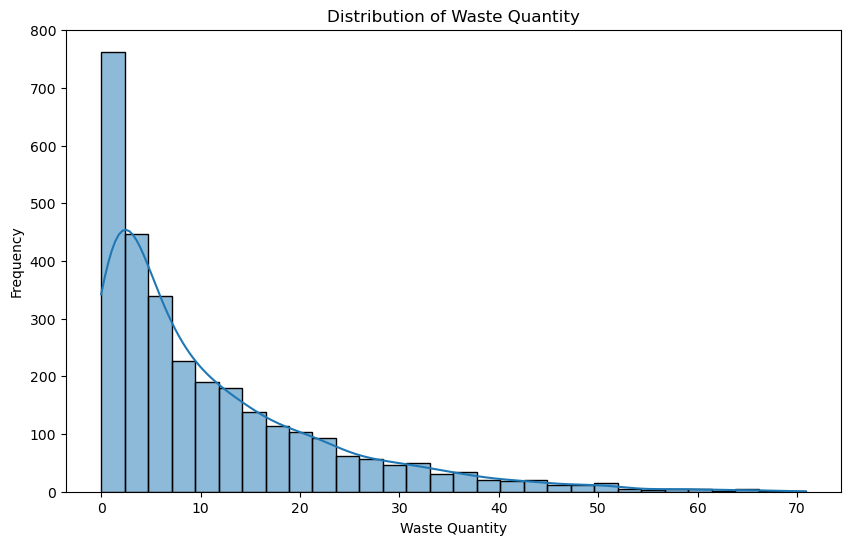

In [16]:
plt.figure(figsize=(10,6))

sns.histplot(df["Waste_Quantity"], bins=30, kde=True)

plt.title("Distribution of Waste Quantity")
plt.xlabel("Waste Quantity")
plt.ylabel("Frequency")

plt.show()

## Observation

- The target variable (`Waste_Quantity`) follows a **right-skewed distribution**.
- Most products generate **low levels of waste**, while a smaller number of products generate significantly higher waste.
- The dataset contains sufficient variation in the target variable, making it suitable for regression modeling.

### Business Insight

The majority of products contribute relatively little food waste. However, a small number of products account for a disproportionately high amount of waste. These products should be prioritized for inventory optimization, pricing strategies, and demand forecasting to reduce financial losses.

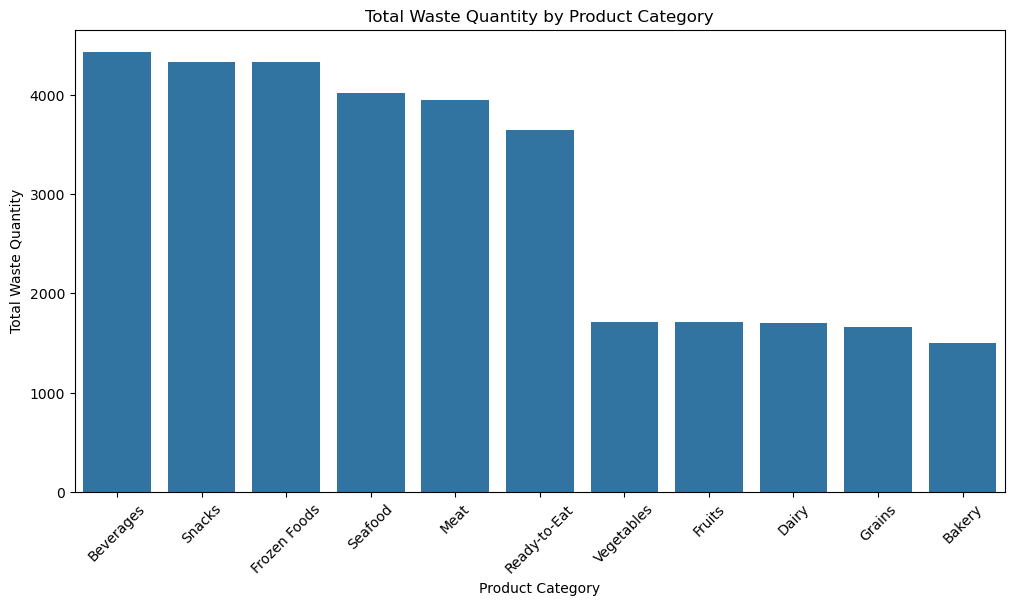

In [17]:
plt.figure(figsize=(12,6))

category_waste = (
    df.groupby("Category")["Waste_Quantity"]
      .sum()
      .sort_values(ascending=False)
)

sns.barplot(
    x=category_waste.index,
    y=category_waste.values
)

plt.title("Total Waste Quantity by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Waste Quantity")
plt.xticks(rotation=45)

plt.show()

## Observation

- The total food waste varies across different product categories.
- Beverages, Snacks, and Frozen Foods contribute the highest total waste.
- Bakery generates the lowest total waste among the product categories.
- The variation in waste across categories indicates that inventory management strategies should be customized for different product types.

### Business Insight

Product categories with higher waste should be prioritized for better demand forecasting, optimized inventory planning, and targeted promotional strategies. Reducing waste in these high-contributing categories can significantly decrease overall food waste and improve profitability.

In [18]:
category_avg = (
    df.groupby("Category")["Waste_Quantity"]
      .mean()
      .sort_values(ascending=False)
)

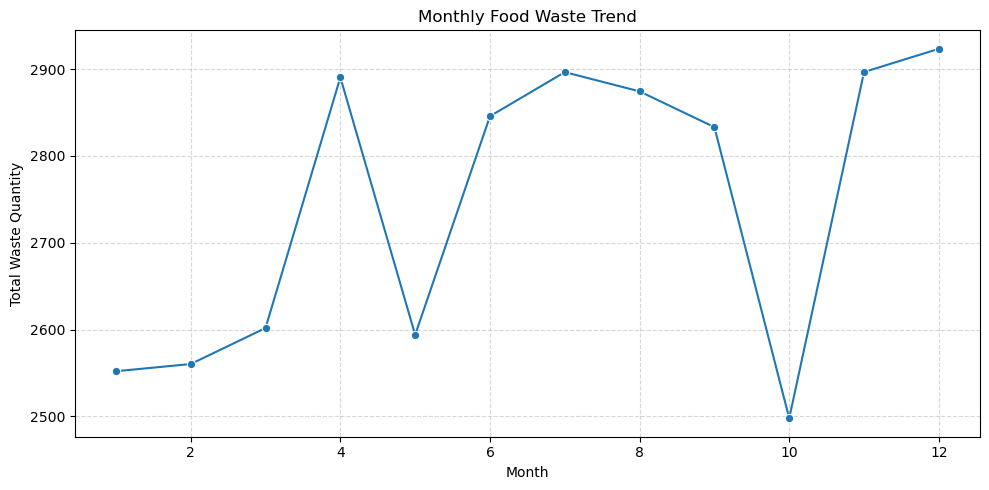

In [19]:
plt.figure(figsize=(10,5))

monthly_waste = (
    df.groupby("Month")["Waste_Quantity"]
      .sum()
)

sns.lineplot(
    x=monthly_waste.index,
    y=monthly_waste.values,
    marker="o"
)

plt.title("Monthly Food Waste Trend")
plt.xlabel("Month")
plt.ylabel("Total Waste Quantity")

# Add grid for better readability
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

plt.show()

## Observation

- Food waste varies across different months.
- October records the lowest total waste.
- November and December show the highest waste quantities.
- The monthly trend indicates seasonal fluctuations in food waste.

### Business Insight

The increase in waste during November and December may be associated with seasonal demand, festive purchasing, or inventory overstocking. Businesses can use these insights to improve inventory planning, adjust purchasing decisions, and implement promotional strategies during high-waste months.

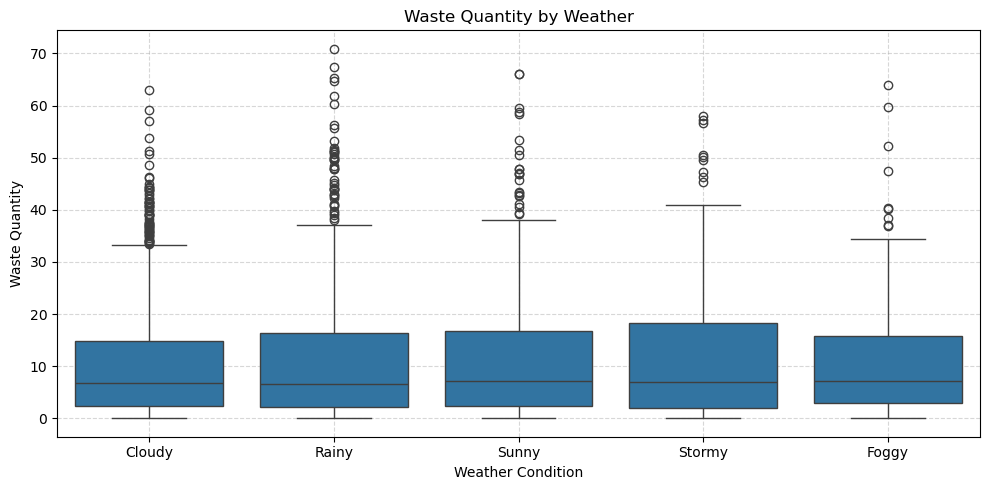

In [20]:
plt.figure(figsize=(10,5))

sns.boxplot(
    x="Weather",
    y="Waste_Quantity",
    data=df
)

plt.title("Waste Quantity by Weather")
plt.xlabel("Weather Condition")
plt.ylabel("Waste Quantity")

plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

plt.show()

## Observation

- Waste quantity varies across different weather conditions.
- Some weather conditions show higher median waste than others.
- A few extreme waste values (outliers) are visible.

### Business Insight

Weather conditions influence inventory movement and product spoilage. Businesses can use weather forecasts to adjust inventory levels and reduce food waste.

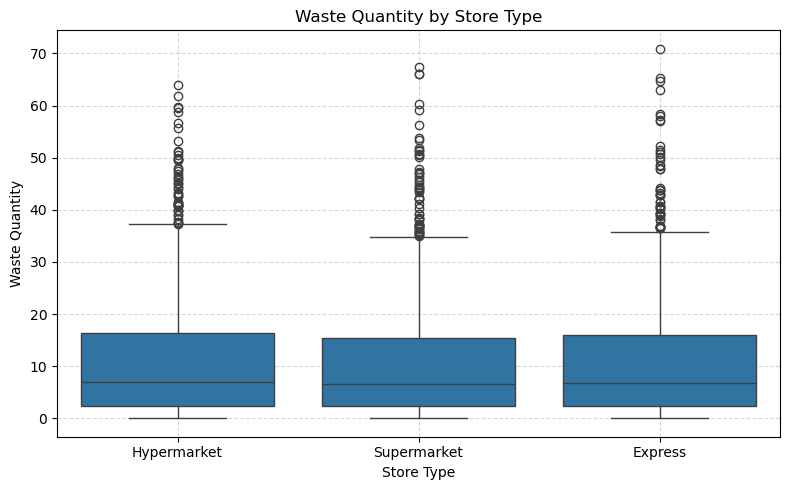

In [21]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x="Store_Type",
    y="Waste_Quantity",
    data=df
)

plt.title("Waste Quantity by Store Type")
plt.xlabel("Store Type")
plt.ylabel("Waste Quantity")

plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

plt.show()

## Observation

- Waste quantity varies across different store types.
- Some store types show a higher median waste quantity than others.
- Outliers indicate that a few stores experience unusually high waste.

### Business Insight

The company can identify store types with consistently higher waste and implement targeted inventory management strategies, staff training, or promotional campaigns to reduce losses.

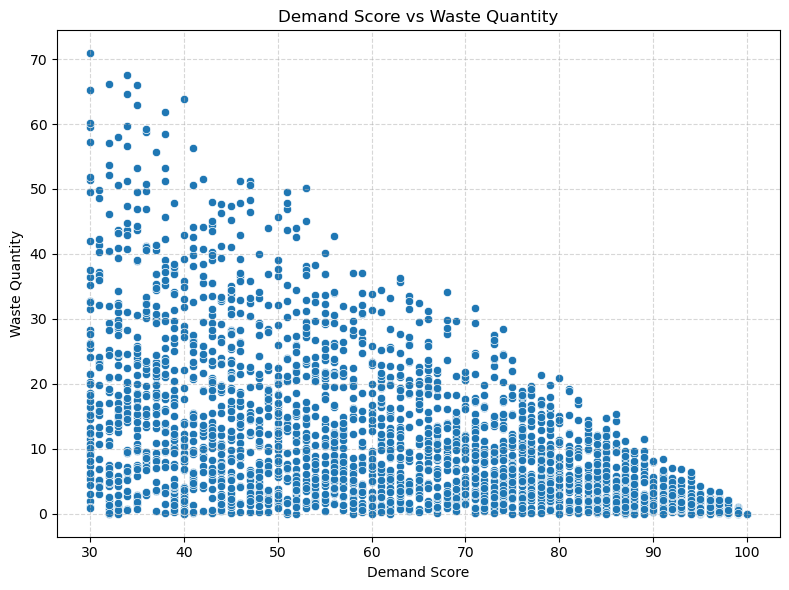

In [22]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    x="Demand_Score",
    y="Waste_Quantity",
    data=df
)

plt.title("Demand Score vs Waste Quantity")
plt.xlabel("Demand Score")
plt.ylabel("Waste Quantity")

plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

plt.show()

## Observation

- The scatter plot shows the relationship between demand score and waste quantity.
- The points indicate whether waste increases or decreases as demand changes.
- Any visible trend can help understand customer demand behavior.

### Business Insight

If higher demand corresponds to lower waste, businesses can improve demand forecasting and inventory planning to minimize food waste.

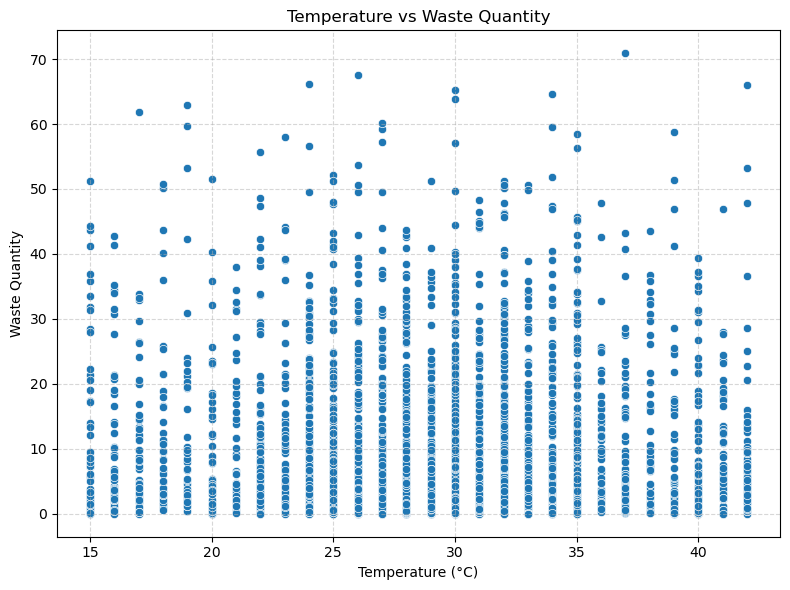

In [23]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    x="Temperature",
    y="Waste_Quantity",
    data=df
)

plt.title("Temperature vs Waste Quantity")
plt.xlabel("Temperature (°C)")
plt.ylabel("Waste Quantity")

plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()

plt.show()

## Observation

- The scatter plot shows the relationship between temperature and food waste.
- If waste increases with temperature, it indicates that warmer conditions may accelerate spoilage.

### Business Insight

Temperature-sensitive products require better storage and monitoring during warmer periods. This can help reduce spoilage and associated financial losses.

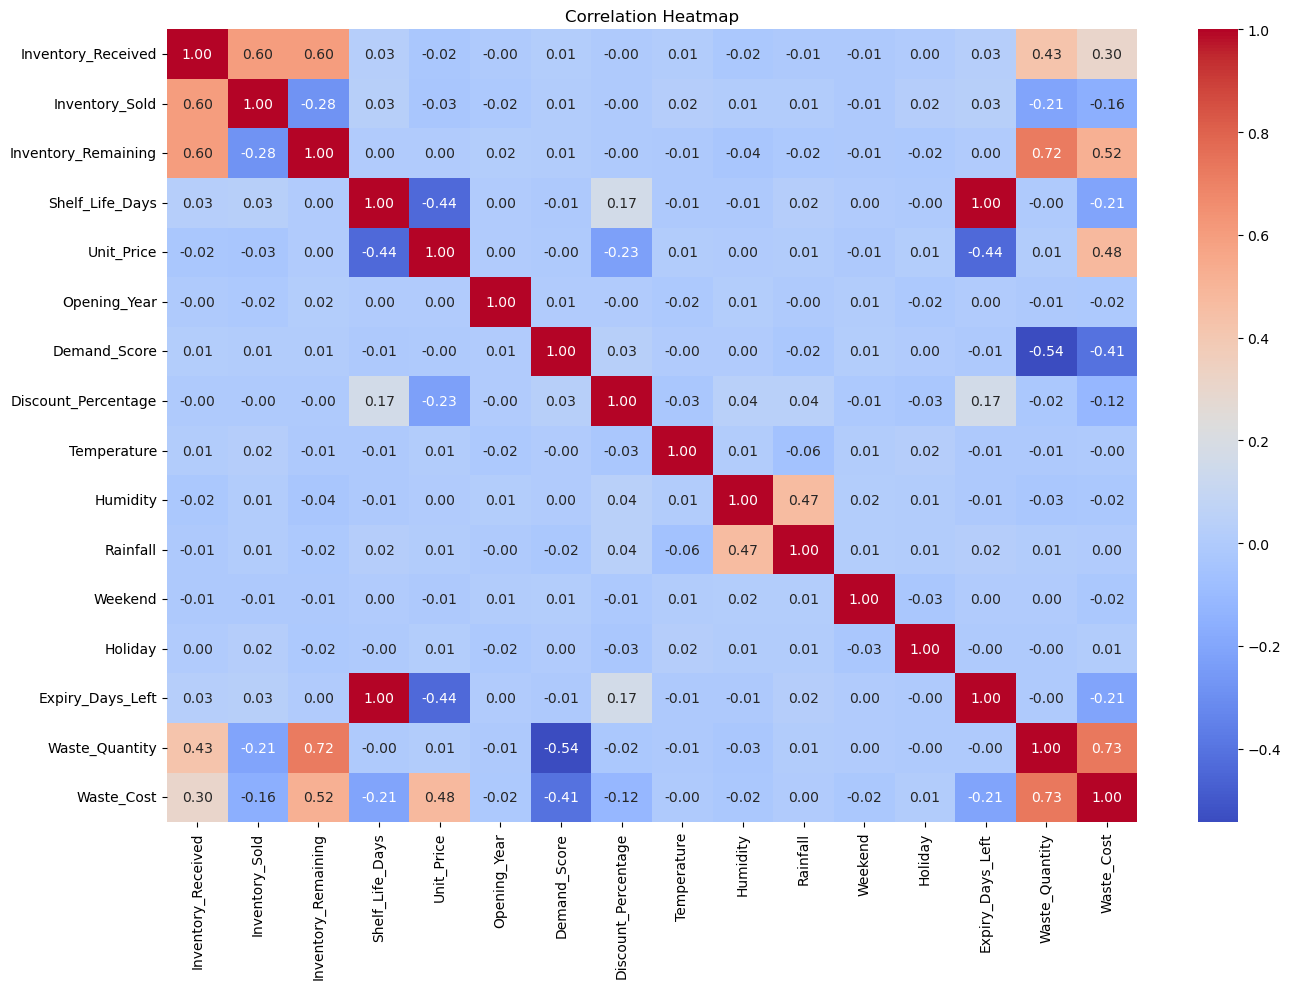

In [24]:
plt.figure(figsize=(14,10))

correlation = df.select_dtypes(include=["int64", "float64"]).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.tight_layout()

plt.show()

## Observation

- The heatmap shows the correlation between all numerical features.
- Features with strong positive or negative correlations with `Waste_Quantity` may be important predictors for the machine learning model.
- Highly correlated independent features should be reviewed before model training.

### Business Insight

Understanding feature relationships helps the business identify the main drivers of food waste and supports better inventory planning and forecasting decisions.